# BIDMC Congestive Heart Failure Database — Exploratory Data Analysis

This notebook explores the BIDMC Congestive Heart Failure Database 
from PhysioNet. It contains long-term ECG recordings from 15 patients 
with severe heart failure (NYHA Class III and IV).

Goal: load raw ECG signals, visualize waveforms, detect heartbeats, 
and extract RR intervals as the foundation for HRV feature engineering 
in the next phase.

In [1]:
import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks

sns.set_theme(style="whitegrid")
print("Libraries loaded successfully")

Libraries loaded successfully


## Loading a BIDMC ECG recording
The BIDMC dataset contains 15 patients each stored as a separate 
record. We will load one record directly from PhysioNet using wfdb 
— no manual download needed. Each record contains two ECG leads 
recorded continuously for several hours.

In [5]:
record = wfdb.rdrecord('chf01', 
                        pn_dir='chfdb/1.0.0')

print(f"Signal names: {record.sig_name}")
print(f"Sampling frequency: {record.fs} Hz")
print(f"Signal shape: {record.p_signal.shape}")
print(f"Duration: {record.p_signal.shape[0] / record.fs / 60:.1f} minutes")

Signal names: ['ECG1', 'ECG2']
Sampling frequency: 250 Hz
Signal shape: (17994491, 2)
Duration: 1199.6 minutes


## Visualizing the raw ECG signal
With 18 million data points we cannot plot the entire recording — 
it would be meaningless visually. Instead we extract a short 
10-second window to see the individual heartbeat waveforms clearly.

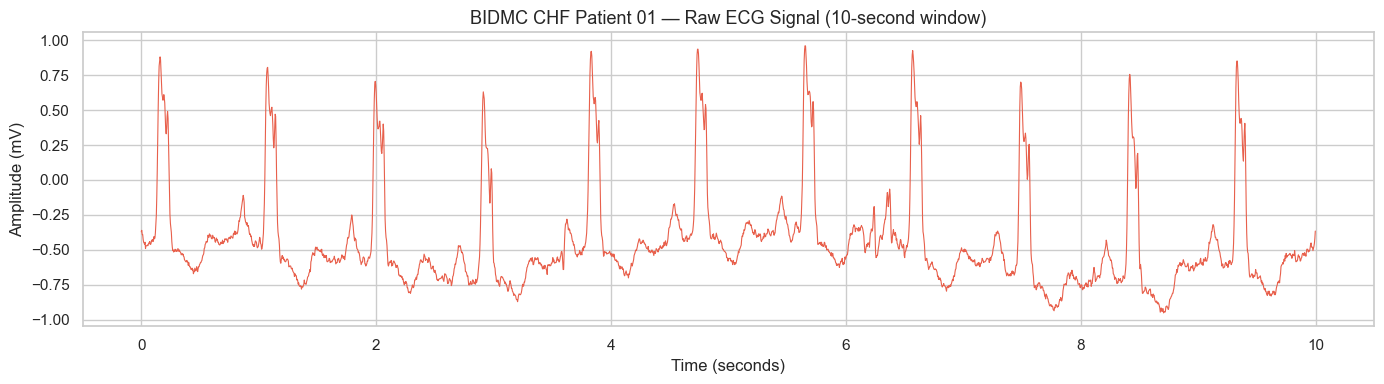

In [6]:
fs = record.fs

start = 60 * fs
end = start + (10 * fs)

signal = record.p_signal[start:end, 0]
time = np.arange(len(signal)) / fs

fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(time, signal, color='#E8604C', linewidth=0.8)

ax.set_title('BIDMC CHF Patient 01 — Raw ECG Signal (10-second window)', 
             fontsize=13)
ax.set_xlabel('Time (seconds)')
ax.set_ylabel('Amplitude (mV)')

plt.tight_layout()
plt.savefig('../reports/figures/02_raw_ecg_signal.png', dpi=150)
plt.show()

## R-peak detection
The R-peak is the sharp spike in each heartbeat — the highest point 
of the QRS complex. Detecting R-peaks gives us the exact timing of 
each heartbeat, which we use to compute RR intervals — the foundation 
of all HRV analysis.

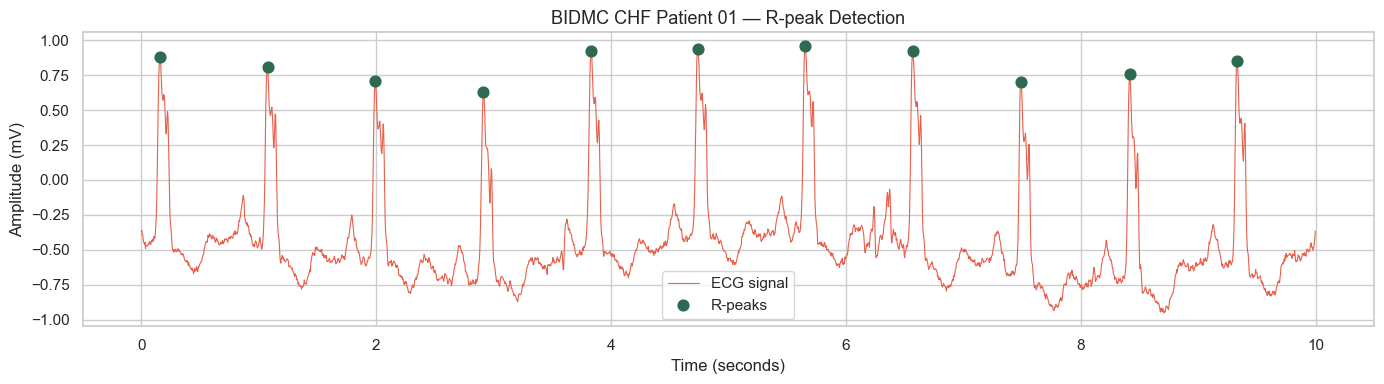

R-peaks detected: 11
Estimated heart rate: 66 bpm


In [7]:
peaks, properties = find_peaks(signal, 
                                height=0.3, 
                                distance=fs*0.4)

fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(time, signal, color='#E8604C', linewidth=0.8, label='ECG signal')
ax.scatter(time[peaks], signal[peaks], 
           color='#2D6A4F', s=60, zorder=5, label='R-peaks')

ax.set_title('BIDMC CHF Patient 01 — R-peak Detection', fontsize=13)
ax.set_xlabel('Time (seconds)')
ax.set_ylabel('Amplitude (mV)')
ax.legend()

plt.tight_layout()
plt.savefig('../reports/figures/02_rpeak_detection.png', dpi=150)
plt.show()

print(f"R-peaks detected: {len(peaks)}")
print(f"Estimated heart rate: {len(peaks) * 6:.0f} bpm")

## RR interval extraction
The RR interval is the time between two consecutive R-peaks. 
It measures exactly how long each heartbeat cycle took. 
A sequence of RR intervals over time is the raw input for 
all HRV (Heart Rate Variability) feature computation in Phase 2.

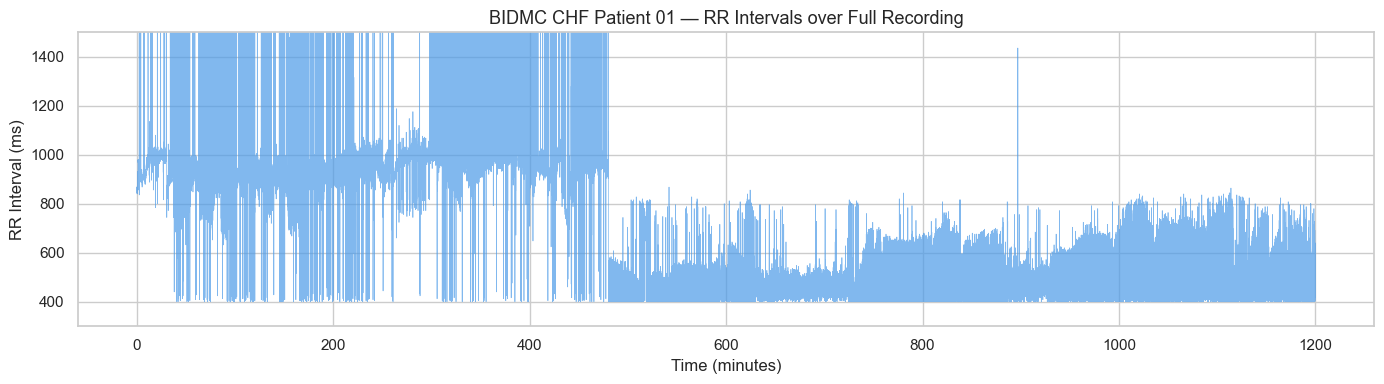

Total beats detected: 115611
Mean RR interval: 622.6 ms
Mean heart rate: 96.4 bpm
Std of RR intervals (SDNN): 420.7 ms


In [8]:
full_signal = record.p_signal[:, 0]

all_peaks, _ = find_peaks(full_signal, 
                           height=0.3, 
                           distance=fs*0.4)

rr_intervals = np.diff(all_peaks) / fs * 1000

time_axis = all_peaks[1:] / fs / 60

fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(time_axis, rr_intervals, 
        color='#4C9BE8', linewidth=0.5, alpha=0.7)

ax.set_title('BIDMC CHF Patient 01 — RR Intervals over Full Recording', 
             fontsize=13)
ax.set_xlabel('Time (minutes)')
ax.set_ylabel('RR Interval (ms)')
ax.set_ylim(300, 1500)

plt.tight_layout()
plt.savefig('../reports/figures/02_rr_intervals.png', dpi=150)
plt.show()

print(f"Total beats detected: {len(all_peaks)}")
print(f"Mean RR interval: {rr_intervals.mean():.1f} ms")
print(f"Mean heart rate: {60000 / rr_intervals.mean():.1f} bpm")
print(f"Std of RR intervals (SDNN): {rr_intervals.std():.1f} ms")

## RR interval analysis findings

- 115,611 beats detected across ~1,200 minutes of recording
- Mean heart rate of 96.4 bpm at rest indicates elevated cardiac 
  workload — consistent with decompensated heart failure
- Raw SDNN of 420.7 ms is artificially elevated by artifact beats 
  and missed detections in the long-term recording
- Dramatic spikes in RR intervals indicate ectopic beats and noise 
  artifacts that must be filtered before HRV feature computation
- RR artifact correction (removing intervals >20% from local median) 
  will be applied during feature engineering in Phase 2

## Key findings

- Successfully loaded a 20-hour ECG recording from a NYHA Class III/IV 
  heart failure patient using wfdb directly from PhysioNet
- Raw ECG waveform shows clearly identifiable PQRST complexes with 
  visible beat-to-beat variability
- R-peak detection identified 11 beats in a clean 10-second window 
  with high visual accuracy — all peaks correctly marked
- Mean heart rate of 96.4 bpm at rest is elevated above normal range 
  (60-80 bpm) — consistent with compensatory tachycardia in heart failure
- Raw RR interval series contains artifacts from patient movement and 
  electrode noise — ectopic beat removal required before HRV analysis
- SDNN artificially elevated at 420.7 ms due to artifacts — true HRV 
  metrics will be computed on cleaned RR intervals in Phase 2